# Hands-on P01: Understanding Images, Image Processing & EDA

**Durasi Hands-on:** ±50 menit (6 langkah singkat mengikuti alur Slide Bab 1–4)  
**Gaya Kode:** Ramah pemula — setiap sel kode dibuat **pendek (5–15 baris)**, satu sel hanya melakukan **satu tugas sederhana**, dan setiap baris dilengkapi penjelasan komentar (`# ...`).

**Apa yang Akan Kita Praktikkan?**
1. **Langkah 1 (Bab 1):** Membuka foto & dataset **MNIST (`28×28`)**, lalu mengintip tabel angka pixel (`0–255`).
2. **Langkah 2 (Bab 1):** Memisahkan 3 lapisan warna **RGB (`Red, Green, Blue`)** dan mengubah foto ke **Grayscale** (hitam-putih).
3. **Langkah 3 (Bab 2):** Menyeragamkan ukuran foto ke `224×224` tanpa gepeng (**Letterbox Padding**) dan menyetarakan skala angka ke `0.0–1.0` (**Normalization**).
4. **Langkah 4 (Bab 4):** Menyaring **3 Jebakan Kamera HP**: foto miring (*EXIF*), file rusak (*Corrupted*), dan foto kembar (*SHA-256*).
5. **Langkah 5 (Bab 3):** Menghitung kesehatan foto (**Class Balance, Brightness, Contrast, & Edge Density Canny**).
6. **Langkah 6 (Laporan):** Membandingkan grafik **Boxplot Polos vs Ramai** dan menyimpan hasil audit ke file `CSV`.

> **Cara Menjalankan:** Tekan `Shift + Enter` pada setiap sel dari atas ke bawah. Pada versi peserta, isi bagian pendek bertanda `# TODO`.

## Setup 1/3: Memanggil Pustaka (*Libraries*) Python
Kita panggil alat-alat bawaan Python untuk membuka gambar (`Pillow`), mengolah tabel angka (`NumPy` & `Pandas`), mendeteksi garis tepi (`OpenCV`), dan menggambar grafik (`Matplotlib`).

In [1]:
import os                           # Untuk membaca pengaturan komputer
import random                       # Untuk mengunci angka acak
import hashlib                      # Untuk membuat sidik jari file (SHA-256)
from pathlib import Path            # Untuk mengatur alamat folder & file

import cv2                          # OpenCV: untuk ubah warna & deteksi garis tepi Canny
import numpy as np                  # NumPy: untuk mengolah matriks/tabel angka pixel
import pandas as pd                 # Pandas: untuk membuat tabel laporan (mirip Excel)
import matplotlib.pyplot as plt     # Matplotlib: untuk menampilkan foto & grafik
from PIL import Image, ImageOps     # Pillow: untuk membuka foto, koreksi EXIF & Letterbox

print("✅ Semua library berhasil dimuat!")

✅ Semua library berhasil dimuat!


## Setup 2/3: Deteksi Google Colab & Mengunci `SEED = 42`
Kita mengunci `SEED = 42` agar hasil eksperimen selalu sama persis setiap kali dijalankan ulang.

In [2]:
# Cek apakah notebook dijalankan di Google Colab atau di komputer lokal
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Kunci angka acak (SEED = 42) agar hasil selalu konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Berjalan di Google Colab :", IN_COLAB)
print("SEED dikunci pada        :", SEED)

Berjalan di Google Colab : False
SEED dikunci pada        : 42


## Setup 3/3: Menentukan Folder Dataset (`data/sample/` & `data/mnist/`)
Kita atur ukuran target gambar (`IMG_SIZE = 224`) dan alamat folder tempat foto latihan disimpan.

In [3]:
# Konfigurasi utama proyek
IMG_SIZE = 224
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"
CLASS_NAMES = ["lingkaran", "persegi", "segitiga", "bintang", "heksagon"]

# Cari folder utama proyek yang memiliki folder "data/"
BASE_DIR = Path(".")
for folder in [Path("."), Path(".."), Path("../.."), Path("../../..")]:
    if (folder / "data").exists():
        BASE_DIR = folder
        break

# Tentukan lokasi folder data sampel, data MNIST, dan folder penyimpanan hasil (results/)
DATA_DIR = BASE_DIR / "data" / "sample"
MNIST_DIR = BASE_DIR / "data" / "mnist"
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Folder Dataset Sampel :", DATA_DIR.resolve())
print("Folder Dataset MNIST  :", MNIST_DIR.resolve())
print("Folder Hasil Audit    :", RESULTS_DIR.resolve())

Folder Dataset Sampel : D:\Haerul\HaloTech-Private-DeepLearning\data\sample
Folder Dataset MNIST  : D:\Haerul\HaloTech-Private-DeepLearning\data\mnist
Folder Hasil Audit    : D:\Haerul\HaloTech-Private-DeepLearning\results


---
## Langkah 1 (8 menit): Membaca Gambar & Mengintip Matriks Pixel (Sesuai Slide 08–13)

Mata manusia melihat foto sebagai bentuk benda, tetapi **komputer hanya membaca tabel angka `0` (gelap) sampai `255` (terang)**.

### Langkah 1.1: Membuka 1 Foto Contoh dari Folder Dataset
Kita ambil 1 foto `.jpg` pertama dari `DATA_DIR` dan membukanya menggunakan `Image.open()`.

In [4]:
# Cari semua file foto .jpg di dalam folder DATA_DIR
all_jpgs = sorted(DATA_DIR.rglob("*.jpg"))
assert len(all_jpgs) > 0, "Tidak ditemukan file .jpg di DATA_DIR"

# Ambil file foto pertama sebagai contoh
sample_img_path = all_jpgs[0]

# Buka foto menggunakan Pillow dan pastikan mode warnanya RGB (3 channel)
img_raw = Image.open(sample_img_path).convert("RGB")

print("Nama file foto :", sample_img_path.name)
print("Ukuran foto    :", img_raw.size, "-> (Lebar, Tinggi)")

Nama file foto : bintang_polos_01.jpg
Ukuran foto    : (256, 256) -> (Lebar, Tinggi)


### Langkah 1.2: Mengubah Foto Menjadi Matriks Angka (`np.array`)
Kita ubah objek gambar `img_raw` menjadi tabel/matriks angka NumPy menggunakan `np.array(img_raw)`.

In [5]:
# Ubah gambar menjadi matriks angka NumPy
arr_raw = np.array(img_raw)

print("Dimensi matriks (.shape) :", arr_raw.shape, "-> (Tinggi, Lebar, Channel)")
print("Tipe data angka (.dtype) :", arr_raw.dtype, "-> angka bulat 0 sampai 255")
print("Nilai paling gelap (min) :", int(arr_raw.min()))
print("Nilai paling terang(max) :", int(arr_raw.max()))

Dimensi matriks (.shape) : (256, 256, 3) -> (Tinggi, Lebar, Channel)
Tipe data angka (.dtype) : uint8 -> angka bulat 0 sampai 255
Nilai paling gelap (min) : 0
Nilai paling terang(max) : 255


### Langkah 1.3: Mengintip Tabel Angka `8×8` Pixel di Tengah Foto
Mari kita potong kotak kecil berukuran `8×8` pixel tepat di tengah foto (` rows 124..132, cols 124..132`), lalu cetak tabel angkanya ke layar!

In [6]:
# Ubah foto ke hitam-putih (1 angka per pixel) agar tabel angkanya mudah dibaca
gray_contoh = cv2.cvtColor(arr_raw, cv2.COLOR_RGB2GRAY)

# Potong kotak kecil 8x8 pixel di bagian tepi atas bintang (baris 64..72, kolom 124..132)
# agar terlihat perbedaan angka latar putih (~243) vs angka objek bintang (~40-122)
patch_8x8 = gray_contoh[64:72, 124:132]

print("Isi matriks 8x8 pixel di tengah foto (angka 0-255):")
print(patch_8x8)

Isi matriks 8x8 pixel di tengah foto (angka 0-255):
[[244 242 244 247 242 242 242 243]
 [242 241 242 244 243 242 242 243]
 [243 242 243 244 243 242 242 243]
 [244 244 244 244 241 242 243 245]
 [243 244 244 243 240 242 245 246]
 [244 244 245 244 241 243 245 245]
 [243 244 244 244 243 242 243 244]
 [240 241 242 242 244 242 241 243]]


Sekarang kita tampilkan foto aslinya bersanding dengan potongan `8×8` pixel tersebut:

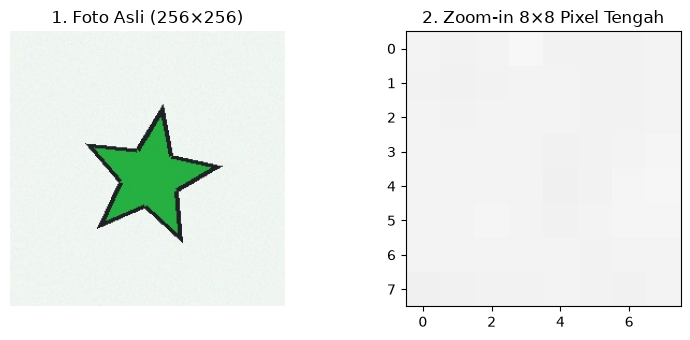

In [7]:
# Tampilkan foto asli di kiri dan potongan 8x8 pixel di kanan
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

axes[0].imshow(arr_raw)
axes[0].set_title("1. Foto Asli (256×256)")
axes[0].axis("off")

axes[1].imshow(patch_8x8, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("2. Zoom-in 8×8 Pixel Tengah")

plt.tight_layout()
plt.show()

### Latihan 1 (`# TODO 1`): Membaca Ukuran Matriks & Nilai RGB di Titik Tengah
1. Ambil ukuran `(img_h, img_w, img_c)` dari `arr_raw.shape`.
2. Ambil 3 angka `[R, G, B]` tepat di pixel tengah foto: `arr_raw[img_h // 2, img_w // 2]`.

In [8]:
# 1. Ambil tinggi, lebar, dan jumlah channel dari arr_raw.shape
img_h, img_w, img_c = arr_raw.shape

# 2. Ambil 3 angka [R, G, B] di baris tengah (img_h // 2) dan kolom tengah (img_w // 2)
center_rgb = arr_raw[img_h // 2, img_w // 2]

assert img_c == 3 and len(center_rgb) == 3
print(f"Tinggi: {img_h} | Lebar: {img_w} | Channel: {img_c}")
print("Nilai [R, G, B] di titik tengah:", center_rgb.tolist())
print("✅ Cek Langkah 1 lolos!")

Tinggi: 256 | Lebar: 256 | Channel: 3
Nilai [R, G, B] di titik tengah: [38, 176, 65]
✅ Cek Langkah 1 lolos!


### Langkah 1.4 (Sesuai Slide 13): Membuka Dataset Asli MNIST (`28×28` Grayscale)
Pada gambar tulisan tangan **MNIST** di folder `data/mnist/`, gambarnya hanya memiliki **1 Channel (*Grayscale*)** berukuran `28 × 28 = 784` angka. Mari kita buka gambar angka **`'7'`**!

In [9]:
# Buka gambar angka '7' dan dua variasi tulisan tangan dari folder data/mnist/
digit_7 = np.array(Image.open(MNIST_DIR / "7" / "mnist_7_01.png").convert("L"))
var_7a = np.array(Image.open(MNIST_DIR / "variants" / "mnist_7_penulis_a.png").convert("L"))
var_7b = np.array(Image.open(MNIST_DIR / "variants" / "mnist_7_penulis_b.png").convert("L"))

print("Ukuran gambar MNIST (.shape) :", digit_7.shape, "-> hanya (Tinggi, Lebar) karena 1 Channel")
print("Total angka dalam 1 gambar   :", digit_7.size, "angka (28 x 28)")
print(f"Nilai pixel tengah (14,14)   : Penulis A = {var_7a[14, 14]} vs Penulis B = {var_7b[14, 14]}")

Ukuran gambar MNIST (.shape) : (28, 28) -> hanya (Tinggi, Lebar) karena 1 Channel
Total angka dalam 1 gambar   : 784 angka (28 x 28)
Nilai pixel tengah (14,14)   : Penulis A = 253 vs Penulis B = 0


Mari kita tampilkan ketiga gambar angka `'7'` dari MNIST tersebut:

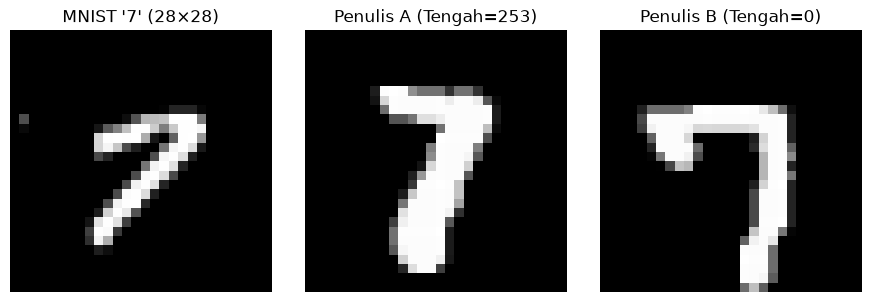

In [10]:
# Tampilkan 3 gambar MNIST '7' secara berjajar
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

axes[0].imshow(digit_7, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("MNIST '7' (28×28)")
axes[0].axis("off")

axes[1].imshow(var_7a, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Penulis A (Tengah={var_7a[14,14]})")
axes[1].axis("off")

axes[2].imshow(var_7b, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"Penulis B (Tengah={var_7b[14,14]})")
axes[2].axis("off")

plt.tight_layout()
plt.show()

---
## Langkah 2 (6 menit): Memisahkan *RGB Channels* & *Grayscale* (Sesuai Slide 14–18)

Foto berwarna **RGB** terdiri dari 3 lapisan angka yang ditumpuk:
- `arr_raw[:, :, 0]` = Lapisan **Merah (*Red*)**
- `arr_raw[:, :, 1]` = Lapisan **Hijau (*Green*)**
- `arr_raw[:, :, 2]` = Lapisan **Biru (*Blue*)**

### Latihan 2A (`# TODO 2A`): Memisahkan 3 Channel R, G, dan B

In [11]:
# Pisahkan masing-masing channel warna dari arr_raw
r_ch = arr_raw[:, :, 0]   # Channel 0: Merah (Red)
g_ch = arr_raw[:, :, 1]   # Channel 1: Hijau (Green)
b_ch = arr_raw[:, :, 2]   # Channel 2: Biru (Blue)

assert r_ch.shape == (img_h, img_w) and g_ch.shape == (img_h, img_w) and b_ch.shape == (img_h, img_w)
print("Ukuran tiap channel:", r_ch.shape, "-> 2D (Tinggi, Lebar)")
print("✅ Cek Latihan 2A lolos!")

Ukuran tiap channel: (256, 256) -> 2D (Tinggi, Lebar)
✅ Cek Latihan 2A lolos!


### Latihan 2B (`# TODO 2B`): Mengubah Foto RGB ke Hitam-Putih (*Grayscale*)
Gunakan `cv2.cvtColor(arr_raw, cv2.COLOR_RGB2GRAY)` untuk meringkas 3 channel warna menjadi 1 channel *Grayscale*.

In [12]:
# Ubah foto RGB (3 channel) menjadi Grayscale (1 channel)
gray_arr = cv2.cvtColor(arr_raw, cv2.COLOR_RGB2GRAY)

assert gray_arr.shape == (img_h, img_w)
print("Shape RGB       :", arr_raw.shape)
print("Shape Grayscale :", gray_arr.shape)
print("✅ Cek Latihan 2B lolos!")

Shape RGB       : (256, 256, 3)
Shape Grayscale : (256, 256)
✅ Cek Latihan 2B lolos!


### Langkah 2.3: Menampilkan Foto Asli, Channel R-G-B, dan Grayscale

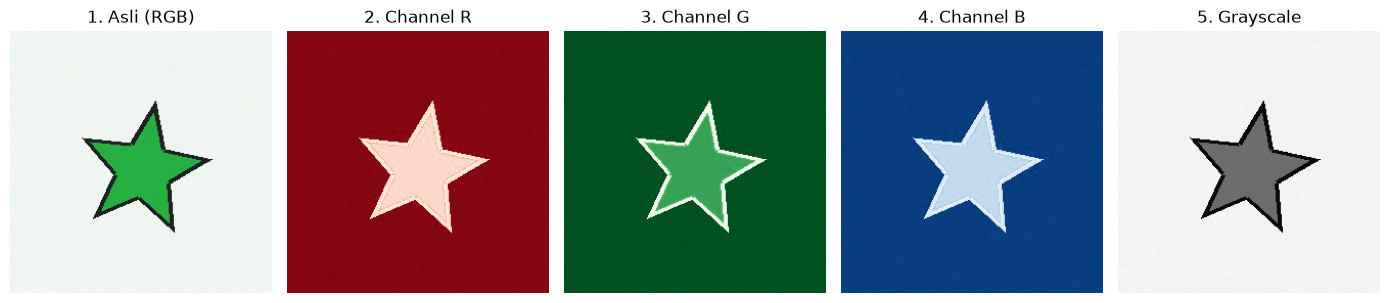

In [13]:
# Tampilkan kelima gambar secara berjajar
fig, axes = plt.subplots(1, 5, figsize=(14, 3))

axes[0].imshow(arr_raw)
axes[0].set_title("1. Asli (RGB)")

axes[1].imshow(r_ch, cmap="Reds")
axes[1].set_title("2. Channel R")

axes[2].imshow(g_ch, cmap="Greens")
axes[2].set_title("3. Channel G")

axes[3].imshow(b_ch, cmap="Blues")
axes[3].set_title("4. Channel B")

axes[4].imshow(gray_arr, cmap="gray")
axes[4].set_title("5. Grayscale")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Langkah 3 (8 menit): *AI Fundamental* & *Image Processing* (Sesuai Slide 20–29)

### Langkah 3.1: Bukti Mengapa Aturan Manual (`If-Else`) Gagal Saat Objek Bergeser (Slide 21)
Mari kita geser foto sejauh 55 pixel ke samping dengan `np.roll()`. Perhatikan bahwa warna di titik tengah langsung berubah dari warna bintang menjadi warna latar putih!

In [14]:
# Geser gambar 55 pixel ke kanan
arr_shifted = np.roll(arr_raw, shift=55, axis=1)

# Bandingkan nilai RGB di titik tengah sebelum dan sesudah digeser
print("RGB titik tengah (awal)    :", arr_raw[img_h // 2, img_w // 2].tolist())
print("RGB titik tengah (digeser) :", arr_shifted[img_h // 2, img_w // 2].tolist())
print("-> Nilainya berubah drastis! Itulah mengapa aturan if-else gagal dan kita butuh Deep Learning.")

RGB titik tengah (awal)    : [38, 176, 65]
RGB titik tengah (digeser) : [238, 244, 240]
-> Nilainya berubah drastis! Itulah mengapa aturan if-else gagal dan kita butuh Deep Learning.


### Latihan 3A (`# TODO 3A`): *Resize* Tanpa Gepeng dengan `ImageOps.pad` (*Letterbox Padding* `224×224`)
Model AI membutuhkan ukuran foto yang seragam (`224 × 224` pixel).
- Di Pillow, kita cukup memanggil **1 baris perintah bawaan**:
  `ImageOps.pad(img_raw, (IMG_SIZE, IMG_SIZE), color=(128, 128, 128))`
- Fungsi ini otomatis mengecilkan foto secara proporsional (anti-gepeng) dan memberi bingkai abu-abu di pinggirnya!

In [15]:
# Cara 1: Resize langsung (rawan membuat foto persegi panjang jadi gepeng)
img_stretch = img_raw.resize((IMG_SIZE, IMG_SIZE))

# Cara 2 (Direkomendasikan): Letterbox Padding otomatis dengan ImageOps.pad
img_letterbox = ImageOps.pad(img_raw, (IMG_SIZE, IMG_SIZE), color=(128, 128, 128))

assert img_letterbox.size == (IMG_SIZE, IMG_SIZE), "Ukuran harus (224, 224)"
print("Ukuran hasil Letterbox Padding:", img_letterbox.size)
print("✅ Cek Latihan 3A lolos!")

Ukuran hasil Letterbox Padding: (224, 224)
✅ Cek Latihan 3A lolos!


### Langkah 3.3: Menampilkan Hasil *Letterbox Padding* (`224×224`)

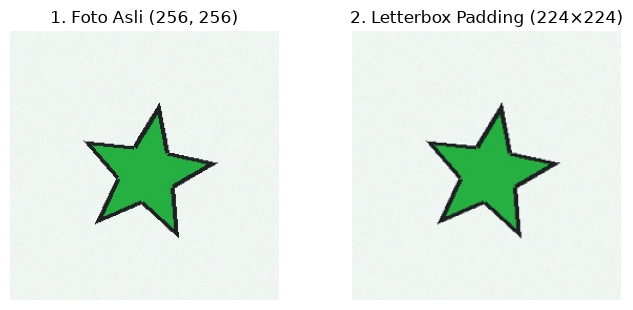

In [16]:
# Tampilkan perbandingan foto asli vs hasil resize 224x224
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))

axes[0].imshow(img_raw)
axes[0].set_title(f"1. Foto Asli {img_raw.size}")
axes[0].axis("off")

axes[1].imshow(img_letterbox)
axes[1].set_title(f"2. Letterbox Padding ({IMG_SIZE}×{IMG_SIZE})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Latihan 3B (`# TODO 3B`): *Normalization* — Mengubah Angka `0–255` Menjadi Desimal `0.0–1.0`
Agar hitungan model AI stabil, kita ubah tipe angka dari `uint8` ke `np.float32` lalu bagi dengan `255.0`.

In [17]:
# Ubah gambar letterbox menjadi matriks angka uint8 (0..255)
arr_u8 = np.array(img_letterbox)

# Ubah tipe ke float32 lalu bagi dengan 255.0 agar skalanya menjadi 0.0 s.d. 1.0
arr_norm = arr_u8.astype(np.float32) / 255.0

assert arr_norm.shape == (IMG_SIZE, IMG_SIZE, 3) and arr_norm.dtype == np.float32
assert 0.0 <= arr_norm.min() and arr_norm.max() <= 1.0
print(f"Sebelum -> tipe: {arr_u8.dtype}   | min: {arr_u8.min()}      | max: {arr_u8.max()}")
print(f"Sesudah -> tipe: {arr_norm.dtype} | min: {arr_norm.min():.4f} | max: {arr_norm.max():.4f}")
print("✅ Cek Latihan 3B lolos!")

Sebelum -> tipe: uint8   | min: 0      | max: 255
Sesudah -> tipe: float32 | min: 0.0000 | max: 1.0000
✅ Cek Latihan 3B lolos!


---
## Langkah 4 (10 menit): Menyaring 3 Jebakan Kamera HP (Sesuai Slide 40–45)

Kita siapkan 3 fungsi pendek untuk mengatasi:
1. **Foto miring (*EXIF Orientation*)** → `ImageOps.exif_transpose(im)`
2. **File foto rusak (*Corrupted File*)** → `im.verify()`
3. **Foto kembar (*Duplicate Image*)** → `hashlib.sha256()`

### Latihan 4A (`# TODO 4A`): Fungsi Pembuka Foto Anti-Miring (*EXIF*)

In [18]:
def load_image_exif_safe(lokasi_foto):
    """Membuka foto dan memutarnya otomatis sesuai catatan EXIF kamera HP."""
    with Image.open(lokasi_foto) as im:
        im_fixed = ImageOps.exif_transpose(im)
        return im_fixed.convert("RGB")


contoh_tegak = load_image_exif_safe(sample_img_path)
assert contoh_tegak.size == img_raw.size
print("✅ Cek Latihan 4A lolos! Ukuran foto tegak:", contoh_tegak.size)

✅ Cek Latihan 4A lolos! Ukuran foto tegak: (256, 256)


### Latihan 4B (`# TODO 4B`): Fungsi Pemeriksa File Rusak (*Corrupted File*)
Gunakan `im.verify()` di dalam blok `try ... except` agar jika ada file yang rusak, program tidak berhenti macet melainkan menandainya sebagai `False`.

In [19]:
def check_image_integrity(lokasi_foto):
    """Mengembalikan (True, lebar, tinggi, '') jika foto sehat, atau (False, 0, 0, error) jika rusak."""
    try:
        # 1. Uji apakah file foto rusak
        with Image.open(lokasi_foto) as im:
            im.verify()

        # 2. Jika sehat, baca ukuran lebar dan tingginya setelah koreksi EXIF
        im_tegak = load_image_exif_safe(lokasi_foto)
        w, h = im_tegak.size
        return True, w, h, ""
    except Exception as err:
        return False, 0, 0, str(err)


sehat, w_uji, h_uji, _ = check_image_integrity(sample_img_path)
assert sehat is True
print(f"✅ Cek Latihan 4B lolos! Status sehat: {sehat} ({w_uji}x{h_uji})")

✅ Cek Latihan 4B lolos! Status sehat: True (256x256)


### Latihan 4C (`# TODO 4C`): Fungsi Sidik Jari File (`SHA-256`) Pendeteksi Foto Kembar
Masukkan `isi_file` ke mesin penghitung hash dengan `h.update(isi_file)` (sesuai **Slide 49**).

In [20]:
def compute_sha256(lokasi_foto):
    """Menghasilkan kode sidik jari unik 64 karakter dari isi file foto."""
    h = hashlib.sha256()
    with open(lokasi_foto, "rb") as f:
        isi_file = f.read()
        h.update(isi_file)
    return h.hexdigest()


contoh_hash = compute_sha256(sample_img_path)
assert len(contoh_hash) == 64
print("✅ Cek Latihan 4C lolos! SHA-256:", contoh_hash)

✅ Cek Latihan 4C lolos! SHA-256: 917e5946f18726f4e48b4c3d16c47005bd8b77a5204307c1900e450759f37100


### Langkah 4.4: Memindai Seluruh 120 File Foto di Folder Dataset
Kita periksa semua file `.jpg` di `DATA_DIR` menggunakan fungsi yang baru kita buat, lalu simpan ke tabel `df_audit`.

In [21]:
records = []

# Periksa setiap file .jpg di dalam folder DATA_DIR
for p in sorted(DATA_DIR.rglob("*.jpg")):
    nama_kondisi = p.parent.name          # Nama sub-folder kondisi ("polos" atau "ramai")
    nama_kelas = p.parent.parent.name     # Nama folder kelas ("bintang", "lingkaran", dll.)

    is_valid, w, h, err = check_image_integrity(p)
    sha = compute_sha256(p) if is_valid else ""

    records.append({
        "file_name": p.name,
        "class": nama_kelas,
        "condition": nama_kondisi,
        "width": w,
        "height": h,
        "is_valid": is_valid,
        "error": err,
        "sha256": sha,
        "abs_path": str(p),
    })

# Buat tabel Pandas DataFrame dari hasil pemindaian
df_audit = pd.DataFrame(records)
print(f"Selesai memindai {len(df_audit)} file! Contoh 5 baris pertama:")
print(df_audit[["file_name", "class", "condition", "is_valid"]].head())

Selesai memindai 120 file! Contoh 5 baris pertama:
              file_name    class condition  is_valid
0  bintang_polos_01.jpg  bintang     polos      True
1  bintang_polos_02.jpg  bintang     polos      True
2  bintang_polos_03.jpg  bintang     polos      True
3  bintang_polos_04.jpg  bintang     polos      True
4  bintang_polos_05.jpg  bintang     polos      True


### Langkah 4.5: Menandai Foto Kembar (*Duplicate*) & Mencetak Ringkasan Audit

In [22]:
# Tandai foto valid yang memiliki kode SHA-256 kembar dengan foto sebelumnya
df_audit["is_duplicate"] = df_audit["is_valid"] & df_audit.duplicated(subset=["sha256"], keep="first")

# Pisahkan foto-foto yang sehat (valid) ke dalam tabel df_valid
df_valid = df_audit[df_audit["is_valid"]].copy()

print("=== RINGKASAN AUDIT DATASET ===")
print("Total file dipindai     :", len(df_audit))
print("Foto sehat (Valid)      :", len(df_valid))
print("Foto rusak (Corrupted)  :", int((~df_audit["is_valid"]).sum()))
print("Foto kembar (Duplicate) :", int(df_audit["is_duplicate"].sum()))
print("✅ Cek Langkah 4 lolos!")

=== RINGKASAN AUDIT DATASET ===
Total file dipindai     : 120
Foto sehat (Valid)      : 119
Foto rusak (Corrupted)  : 1
Foto kembar (Duplicate) : 1
✅ Cek Langkah 4 lolos!


---
## Langkah 5 (12 menit): EDA Kesehatan Dataset (Sesuai Slide 31–39)

### Langkah 5.1: Memeriksa Keseimbangan Jumlah Foto (*Class Balance* · Issue #1)
Kita hitung jumlah foto sehat (`df_valid`) di setiap kelas dan kondisi latar dengan `pd.crosstab()`.

condition  polos  ramai
class                  
bintang       12     12
heksagon      12     12
lingkaran     12     12
persegi       12     12
segitiga      12     11


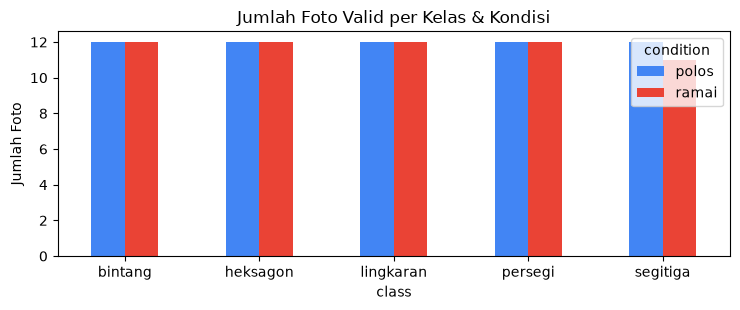

In [23]:
# Buat tabel silang jumlah foto per Kelas vs Kondisi Latar (polos / ramai)
ct = pd.crosstab(df_valid["class"], df_valid["condition"])
print(ct)

# Tampilkan dalam bentuk grafik batang (bar chart)
ax = ct.plot(kind="bar", figsize=(7.5, 3.2), color=["#4285F4", "#EA4335"], rot=0)
ax.set_title("Jumlah Foto Valid per Kelas & Kondisi")
ax.set_ylabel("Jumlah Foto")
plt.tight_layout()
plt.show()

### Latihan 5 (`# TODO 5`): Menghitung *Brightness*, *Contrast*, dan *Edge Density* (Issue #2 & #3)
Untuk setiap foto yang valid, kita hitung 3 angka kesehatannya:
1. **`brightness`**: Rata-rata terang seluruh pixel (`float(np.mean(gray))`)
2. **`contrast`**: Ketajaman beda gelap-terang (`float(np.std(gray))`)
3. **`edge_density`**: Proporsi pixel garis tepi Canny (`float(np.mean(edges > 0))`)

In [24]:
def compute_image_metrics(lokasi_foto):
    """Menghitung (brightness, contrast, edge_density) dari sebuah foto."""
    im = load_image_exif_safe(lokasi_foto)
    gray = np.array(im.convert("L"))

    # 1. Rata-rata terang (Brightness)
    brightness = float(np.mean(gray))

    # 2. Simpangan baku terang-gelap (Contrast)
    contrast = float(np.std(gray))

    # 3. Proporsi garis tepi Canny (Edge Density)
    edges = cv2.Canny(gray, 100, 200)
    edge_density = float(np.mean(edges > 0))

    return brightness, contrast, edge_density


# Hitung ketiga angka tersebut untuk seluruh 119 foto valid
hasil_metrik = [compute_image_metrics(p) for p in df_valid["abs_path"]]
df_valid[["brightness", "contrast", "edge_density"]] = hasil_metrik

assert df_valid["brightness"].between(0, 255).all()
assert df_valid["edge_density"].between(0, 1).all()
print("✅ Cek Langkah 5 lolos! Contoh 5 baris hasil perhitungan:")
print(df_valid[["file_name", "condition", "brightness", "contrast", "edge_density"]].head())

✅ Cek Langkah 5 lolos! Contoh 5 baris hasil perhitungan:
              file_name condition  brightness   contrast  edge_density
0  bintang_polos_01.jpg     polos  229.909775  43.772527      0.013962
1  bintang_polos_02.jpg     polos  232.213120  40.134723      0.012283
2  bintang_polos_03.jpg     polos  227.881851  46.099350      0.015106
3  bintang_polos_04.jpg     polos  225.046600  46.745915      0.015213
4  bintang_polos_05.jpg     polos  229.768646  42.996395      0.014771


### Langkah 5.3: Membandingkan 1 Foto *Polos* vs 1 Foto *Ramai* (Histogram & Garis Tepi Canny · Slide 33–36)
Mari kita ambil 1 foto berlatar **Polos** dan 1 foto berlatar **Ramai** untuk membandingkan grafik **Histogram** dan peta **Canny Edges**-nya.

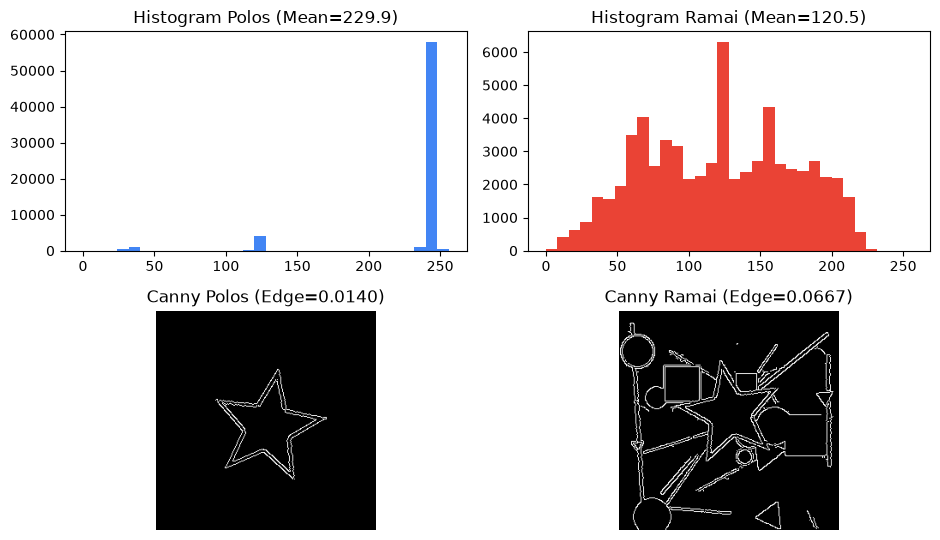

In [25]:
# Ambil 1 foto contoh berlatar polos dan 1 foto contoh berlatar ramai
foto_polos = df_valid[df_valid["condition"] == "polos"].iloc[0]
foto_ramai = df_valid[df_valid["condition"] == "ramai"].iloc[0]

# Buka kedua foto dalam mode Grayscale (hitam-putih)
gray_p = np.array(load_image_exif_safe(foto_polos["abs_path"]).convert("L"))
gray_r = np.array(load_image_exif_safe(foto_ramai["abs_path"]).convert("L"))

# Tampilkan perbandingan Histogram (atas) dan Garis Tepi Canny (bawah)
fig, axes = plt.subplots(2, 2, figsize=(9.5, 5.5))

axes[0, 0].hist(gray_p.ravel(), bins=32, range=(0, 256), color="#4285F4")
axes[0, 0].set_title(f"Histogram Polos (Mean={gray_p.mean():.1f})")

axes[0, 1].hist(gray_r.ravel(), bins=32, range=(0, 256), color="#EA4335")
axes[0, 1].set_title(f"Histogram Ramai (Mean={gray_r.mean():.1f})")

axes[1, 0].imshow(cv2.Canny(gray_p, 100, 200), cmap="gray")
axes[1, 0].set_title(f"Canny Polos (Edge={foto_polos['edge_density']:.4f})")
axes[1, 0].axis("off")

axes[1, 1].imshow(cv2.Canny(gray_r, 100, 200), cmap="gray")
axes[1, 1].set_title(f"Canny Ramai (Edge={foto_ramai['edge_density']:.4f})")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

---
## Langkah 6 (6 menit): Ringkasan *Polos vs Ramai* & Simpan Laporan (Sesuai Slide 34, 36 & 50)

### Langkah 6.1: Tabel Rata-Rata Statistik *Polos vs Ramai* (119 Foto Valid)

In [26]:
# Hitung jumlah foto (count), rata-rata (mean), dan simpangan baku (std) untuk Polos vs Ramai
summary = (
    df_valid.groupby("condition")[["brightness", "contrast", "edge_density"]]
    .agg(["count", "mean", "std"])
    .round(4)
)

print("=== RINGKASAN STATISTIK: POLOS VS RAMAI ===")
print(summary)

=== RINGKASAN STATISTIK: POLOS VS RAMAI ===
          brightness                    contrast                   \
               count      mean      std    count     mean     std   
condition                                                           
polos             60  228.1104   6.1898       60  45.2098  8.7442   
ramai             59  127.2126  10.8331       59  54.6922  4.9084   

          edge_density                  
                 count    mean     std  
condition                               
polos               60  0.0121  0.0019  
ramai               59  0.0853  0.0220  


### Langkah 6.2: Grafik *Boxplot* Perbandingan *Polos vs Ramai*
Kita pisahkan tabel menjadi `df_polos` dan `df_ramai`, lalu gambar 3 grafik **Boxplot** (*Brightness, Contrast, Edge Density*) secara langsung.

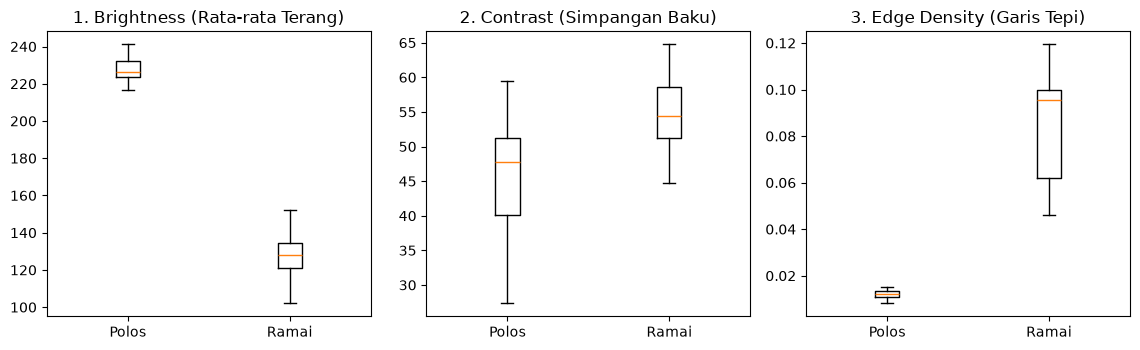

In [27]:
# Pisahkan data kelompok latar Polos dan latar Ramai
df_polos = df_valid[df_valid["condition"] == "polos"]
df_ramai = df_valid[df_valid["condition"] == "ramai"]

# Buat 3 grafik Boxplot berjajar
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))

axes[0].boxplot([df_polos["brightness"], df_ramai["brightness"]], tick_labels=["Polos", "Ramai"])
axes[0].set_title("1. Brightness (Rata-rata Terang)")

axes[1].boxplot([df_polos["contrast"], df_ramai["contrast"]], tick_labels=["Polos", "Ramai"])
axes[1].set_title("2. Contrast (Simpangan Baku)")

axes[2].boxplot([df_polos["edge_density"], df_ramai["edge_density"]], tick_labels=["Polos", "Ramai"])
axes[2].set_title("3. Edge Density (Garis Tepi)")

plt.tight_layout()

# Simpan grafik ke folder results/
plot_path = RESULTS_DIR / "p01_eda_polos_vs_ramai.png"
fig.savefig(plot_path, dpi=150)
plt.show()

### Langkah 6.3: Menyimpan Tabel Laporan Audit ke File CSV
Terakhir, kita simpan tabel `df_valid` dan `summary` ke dalam folder `results/`.

In [28]:
# Tentukan lokasi file CSV di dalam folder results/
audit_csv = RESULTS_DIR / "p01_audit_metadata.csv"
summary_csv = RESULTS_DIR / "p01_eda_summary.csv"

# Simpan tabel ke file CSV
df_valid.to_csv(audit_csv, index=False)
summary.to_csv(summary_csv)

assert audit_csv.exists() and summary_csv.exists() and plot_path.exists()
print("1. Tabel Audit disimpan ke    :", audit_csv)
print("2. Tabel Ringkasan disimpan ke:", summary_csv)
print("3. Grafik Boxplot disimpan ke :", plot_path)
print("✅ Seluruh langkah Hands-on P01 selesai!")

1. Tabel Audit disimpan ke    : ..\..\..\results\p01_audit_metadata.csv
2. Tabel Ringkasan disimpan ke: ..\..\..\results\p01_eda_summary.csv
3. Grafik Boxplot disimpan ke : ..\..\..\results\p01_eda_polos_vs_ramai.png
✅ Seluruh langkah Hands-on P01 selesai!


### Mini-Challenge: Diskusi Kasus Polos vs Ramai (Sesuai Slide 50)
Berdasarkan tabel dan grafik *Boxplot* di atas:
1. Kondisi mana yang lebih sulit ditebak oleh AI nantinya: **Polos** atau **Ramai**? Mengapa?
2. Jika AI hanya dilatih dengan foto **Polos**, apa yang terjadi saat ia diuji melihat foto **Ramai**?
3. Apa strategi kita agar AI pintar di kedua kondisi sekaligus serta bebas dari *Data Leakage*?

## Referensi Belajar Mandiri (Video YouTube & Modul Berurutan · Slide 58–59)

1. [3Blue1Brown — *But what is a neural network? (Ch. 1)*](https://www.youtube.com/watch?v=aircAruvnKk) *(menit 00:00–05:30: gambar MNIST 28×28 sebagai grid angka)*
2. [Keith Galli — *Complete Python NumPy Tutorial*](https://www.youtube.com/watch?v=GB9ByFAIAH4)
3. [IBM Technology — *AI, Machine Learning, Deep Learning & GenAI Explained*](https://www.youtube.com/watch?v=qYNweeDHiyU)
4. [Simplilearn — *Deep Learning In 5 Minutes*](https://www.youtube.com/watch?v=6M5VXKLf4D4)
5. [Simplilearn — *What is Artificial Intelligence? (5 Minutes)*](https://www.youtube.com/watch?v=ad79nYk2keg)
6. [Corey Schafer — *Python Tutorial: Image Manipulation with Pillow*](https://www.youtube.com/watch?v=6Qs3w1uYujo)
7. [freeCodeCamp.org — *OpenCV Course - Full Tutorial with Python*](https://www.youtube.com/watch?v=oXlwWbU8l2o)
8. [Murtaza's Workshop — *Learn OpenCV in 3 Hours with Python*](https://www.youtube.com/watch?v=WQeoO7MI0Bs)
9. [Computerphile — *How Blurs & Filters Work*](https://www.youtube.com/watch?v=C_zFhWdM4ic)
10. [Computerphile — *Finding the Edges (Sobel Operator)*](https://www.youtube.com/watch?v=uihBwtPIBxM)
11. [Computerphile — *Canny Edge Detector*](https://www.youtube.com/watch?v=sRF9t8LqXW4)
12. [DigitalSreeni — *Python for Microscopists* (GitHub)](https://github.com/bnsreenu/python_for_microscopists)
13. [Coursera (DeepLearning.AI) — *Convolutional Neural Networks (Week 1)*](https://www.coursera.org/learn/convolutional-neural-networks)
14. [Kaggle Learn — *Data Leakage (Tutorial Interaktif)*](https://www.kaggle.com/code/alexisbcook/data-leakage)
15. [IBM — *What is Data Leakage in Machine Learning?*](https://www.ibm.com/topics/data-leakage)